C:\Users\Usuario\AppData\Local\Temp\ipykernel_11780\1482800284.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


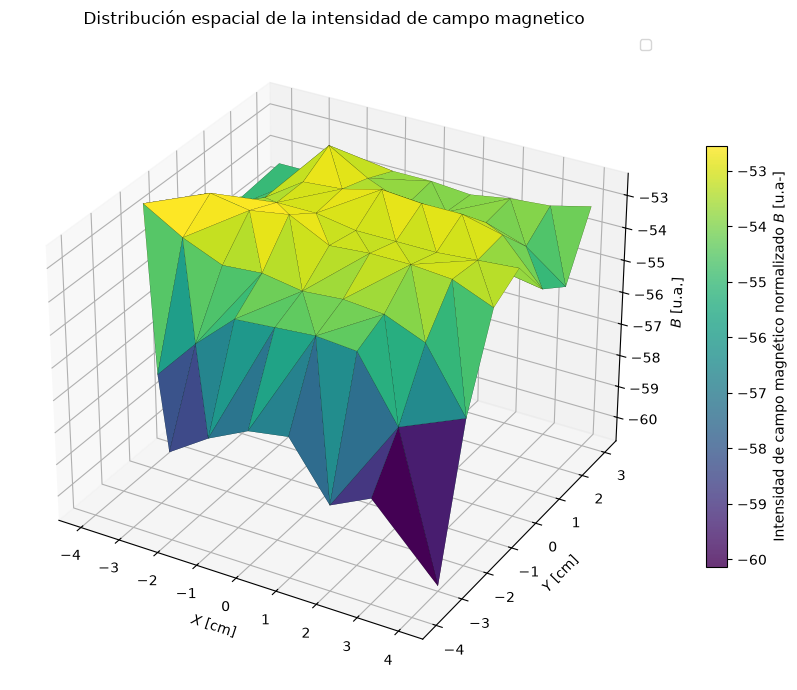

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import griddata


df = pd.read_excel("2026-10-09_HallEffect.xlsx", sheet_name="B2")

x = df["X_cm"].to_numpy()
y = -df["Y_cm"].to_numpy()
z = -df["B_mT"].to_numpy()
# z = (z - np.min(z)) / (np.max(z) - np.min(z))


xi = np.linspace(x.min(), x.max(), 1000)
yi = np.linspace(y.min(), y.max(), 1000)

X, Y = np.meshgrid(xi, yi)


Z = griddata((x, y), z, (X, Y), method="linear")


fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")


superficie = ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    alpha=0.8,
    edgecolor="none"
)

surf = ax.plot_trisurf(
    x, y, z,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.1,
    antialiased=True
)

ax.set_xlabel(r"$X$ [cm]")
ax.set_ylabel(r"$Y$ [cm]")
ax.set_zlabel(r"$B$ [u.a.]")

ax.set_title("Distribución espacial de la intensidad de campo magnetico")

fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.65,
    label=r"Intensidad de campo magnético normalizado $B$ [u.a-]"
)

ax.legend()
plt.tight_layout()
plt.show()
